# Model 2 · 2. Preprocessing dan ekstraksi ciri

Model machine learning klasik (Random Forest dan kawan-kawan) tidak bisa membaca gambar langsung.
Setiap gambar diubah menjadi **60 angka (ciri)**. Rumusnya ada di `src/ciri_jerawat.py` dan dipakai juga oleh aplikasi,
jadi cara mengolah gambar saat training dan saat dipakai **sama persis**.

Langkah preprocessing:
1. Ubah ke RGB, lalu **resize ke 64x64** (BICUBIC), skala 0-1.
2. Ubah ke ruang warna **HSV** dan **Lab**.
3. Hitung **48 ciri warna** dan **12 ciri titik** (bagian tengah dibanding kulit di pinggir).
4. Simpan semua ciri ke `hasil/model2/ciri_warna_titik.npz`.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from skimage.color import rgb2hsv, rgb2lab

from ciri_jerawat import JARAK, NAMA_CIRI, TENGAH, TEPI, UKURAN, ciri

KELAS = ['Blackheads', 'Cyst', 'Papules', 'Pustules', 'Whiteheads']
SIMPAN = ROOT / 'hasil' / 'model2'
SIMPAN.mkdir(parents=True, exist_ok=True)


def daftar(bagian, hanya_potongan=False):
    p = [(f, i) for i, k in enumerate(KELAS) for f in sorted((DATA / 'jenis_v3' / bagian / k).glob('*'))
         if not hanya_potongan or f.name.startswith('C_')]
    return [f for f, _ in p], np.array([i for _, i in p])


P, Y = {}, {}
P['latih'], Y['latih'] = daftar('train')
P['val'], Y['val'] = daftar('val', hanya_potongan=True)
P['ujian'], Y['ujian'] = daftar('test_potongan')
print({k: len(v) for k, v in P.items()})

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


{'latih': 8618, 'val': 802, 'ujian': 795}


## 1. Langkah preprocessing pada satu gambar per jenis

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.19529412686824799..1.0000000238418578].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.31529414653778076..1.0000000238418578].


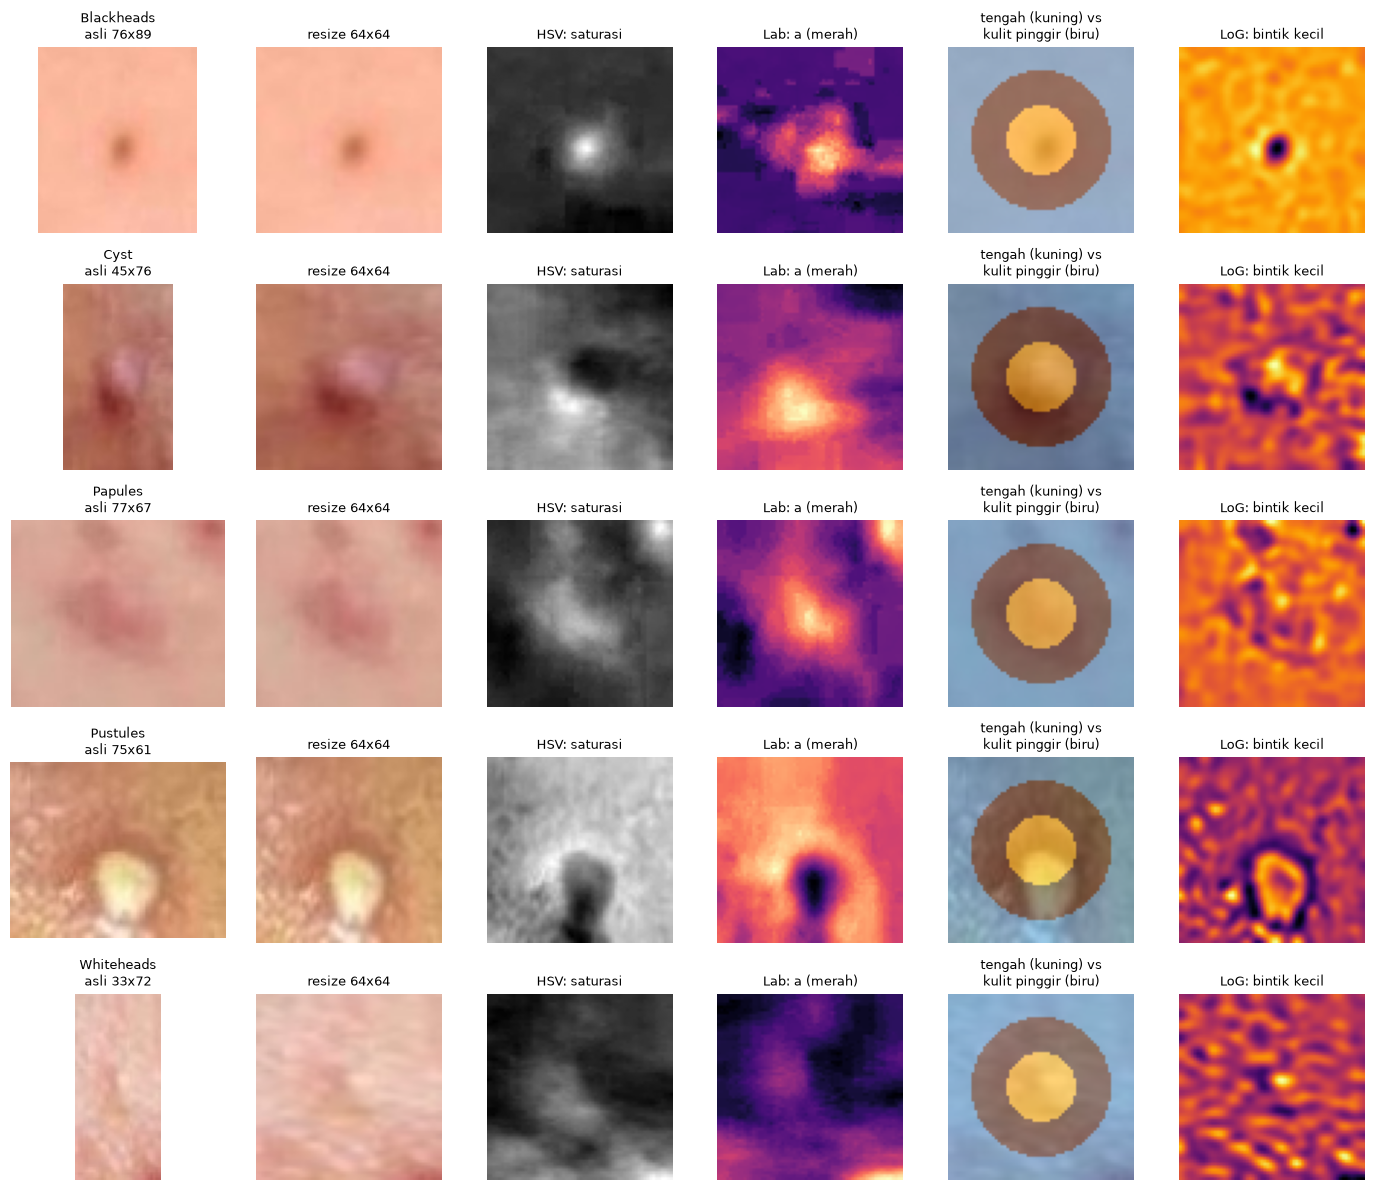

In [2]:
contoh = [P['latih'][np.where(Y['latih'] == i)[0][5]] for i in range(5)]
fig, ax = plt.subplots(5, 6, figsize=(14, 12))
for r, p in enumerate(contoh):
    asli = Image.open(p).convert('RGB')
    rgb = np.asarray(asli.resize((UKURAN, UKURAN), Image.BICUBIC), np.float32) / 255
    hsv, lab = rgb2hsv(rgb), rgb2lab(rgb)
    bintik = -ndimage.gaussian_laplace(lab[..., 0], 2)
    zona = np.zeros((UKURAN, UKURAN, 3)); zona[TENGAH] = (1, 0.8, 0); zona[TEPI] = (0, 0.6, 1)
    gambar = [(asli, f'{KELAS[r]}\nasli {asli.size[0]}x{asli.size[1]}', None), (rgb, 'resize 64x64', None),
              (hsv[..., 1], 'HSV: saturasi', 'gray'), (lab[..., 1], 'Lab: a (merah)', 'magma'),
              (rgb * 0.6 + zona * 0.4, 'tengah (kuning) vs\nkulit pinggir (biru)', None), (bintik, 'LoG: bintik kecil', 'inferno')]
    for c, (g, judul, cmap) in enumerate(gambar):
        ax[r, c].imshow(g, cmap=cmap); ax[r, c].set_title(judul, fontsize=9); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

## 2. Daftar 60 ciri

| Kelompok | Jumlah | Isi |
|---|---|---|
| Histogram HSV | 28 | sebaran warna (H 12), kepekatan (S 8), kecerahan (V 8) |
| Statistik Lab dan RGB | 12 | rata-rata dan sebaran tiap saluran |
| Porsi piksel | 3 | piksel merah, putih, gelap |
| Kontras | 5 | kotak tengah dibanding pinggir (L, a, b, S, V) |
| **Titik (12)** | 12 | lingkaran tengah (r < 12) dibanding kulit pinggir (r > 24): titik terang, porsi putih dan kuning, bintik kecil dan besar (Laplacian of Gaussian), kemerahan, titik gelap |

Ciri titik dibuat karena perbedaan utama antar jenis ada di **tengah jerawat**: titik putih/kuning (Whiteheads, Pustules),
titik hitam (Blackheads), atau benjolan merah tanpa titik (Papules, Cyst).

In [3]:
print(len(NAMA_CIRI), 'ciri:')
for i in range(0, 60, 6):
    print('  ' + ', '.join(NAMA_CIRI[i:i + 6]))

60 ciri:
  hist_H0, hist_H1, hist_H2, hist_H3, hist_H4, hist_H5
  hist_H6, hist_H7, hist_H8, hist_H9, hist_H10, hist_H11
  hist_S0, hist_S1, hist_S2, hist_S3, hist_S4, hist_S5
  hist_S6, hist_S7, hist_V0, hist_V1, hist_V2, hist_V3
  hist_V4, hist_V5, hist_V6, hist_V7, L_rata, a_rata
  b_rata, L_sebar, a_sebar, b_sebar, R_rata, G_rata
  B_rata, R_sebar, G_sebar, B_sebar, porsi_merah, porsi_putih
  porsi_gelap, kontras_L, kontras_a, kontras_b, kontras_S, kontras_V
  titik_terang_maks, titik_terang_p95, titik_porsi_putih, titik_porsi_kuning, titik_bintik_maks, titik_bintik_pusat
  titik_bintik_besar_maks, titik_bintik_besar_min, titik_merah_tengah, porsi_merah_kulit, porsi_merah_dekat, titik_gelap_tengah


## 3. Hitung ciri semua gambar
Sekitar 3 menit. Kalau sudah pernah dihitung, dimuat dari file.

In [4]:
CACHE = SIMPAN / 'ciri_warna_titik.npz'
if CACHE.exists():
    z = np.load(CACHE)
    X = {k: z[k] for k in P}
    print('ciri dimuat dari', CACHE)
else:
    t0 = time.time()
    X = {k: np.stack([ciri(Image.open(p)) for p in P[k]]) for k in P}
    np.savez_compressed(CACHE, **X, **{'y_' + k: Y[k] for k in P})
    print(f'selesai dalam {time.time() - t0:.0f} detik, disimpan ke', CACHE)
for k in P:
    assert len(X[k]) == len(P[k])
    print(k, X[k].shape)
pd.DataFrame(X['latih'][:5], columns=NAMA_CIRI).round(3).iloc[:, [0, 28, 31, 40, 48, 49, 50, 52, 56]]

selesai dalam 75 detik, disimpan ke C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL\hasil\model2\ciri_warna_titik.npz
latih (8618, 60)
val (802, 60)
ujian (795, 60)


,hist_H0,L_rata,L_sebar,porsi_merah,titik_terang_maks,titik_terang_p95,titik_porsi_putih,titik_bintik_maks,titik_merah_tengah
0,1.000,46.337002,2.488,0.000,3.893,0.726,0.0,0.535,0.352
1,0.753,56.509998,2.286,0.000,1.008,0.357,0.0,0.360,2.528
2,0.985,61.254002,5.393,0.000,1.606,1.051,0.0,0.311,-1.588
3,0.906,30.356001,6.920,0.000,5.849,3.138,0.0,1.059,0.430
4,0.999,54.008999,21.020,0.927,15.660,12.200,0.0,1.049,2.977


## 4. Apakah ciri titik membedakan jenis?

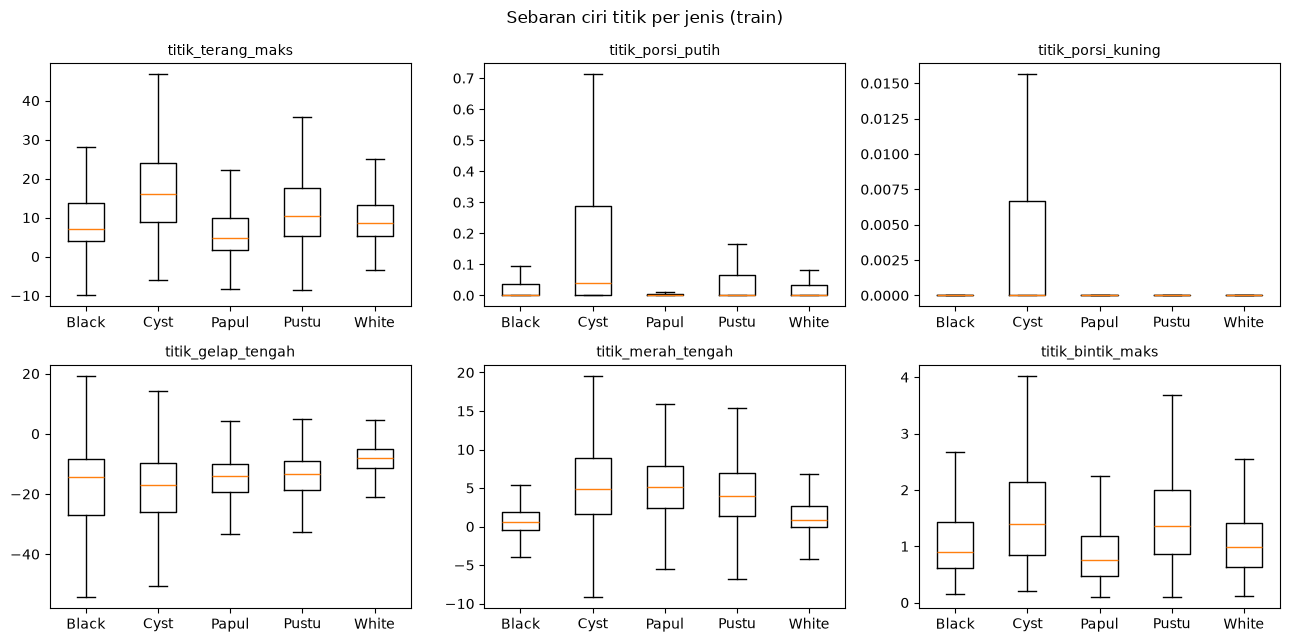

In [5]:
pilih = ['titik_terang_maks', 'titik_porsi_putih', 'titik_porsi_kuning', 'titik_gelap_tengah', 'titik_merah_tengah', 'titik_bintik_maks']
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a, n in zip(ax.flat, pilih):
    j = NAMA_CIRI.index(n)
    a.boxplot([X['latih'][Y['latih'] == i, j] for i in range(5)], showfliers=False)
    a.set_xticks(range(1, 6), [k[:5] for k in KELAS]); a.set_title(n, fontsize=10)
plt.suptitle('Sebaran ciri titik per jenis (train)'); plt.tight_layout(); plt.show()

Contoh yang terlihat: `titik_gelap_tengah` paling rendah di Blackheads (titik hitam), `titik_merah_tengah` tinggi di Papules/Cyst,
`titik_porsi_putih` tinggi di Whiteheads/Pustules. Kotak-kotaknya tetap saling tumpang tindih, jadi model perlu
menggabungkan banyak ciri sekaligus.

**Hasil dari percobaan sebelumnya:** menambah 12 ciri titik menaikkan Random Forest dari macro F1 0,657 ke 0,707 di val.
Ciri tekstur (LBP/GLCM) dan ukuran potongan sudah dicoba dan **tidak** menaikkan nilai, jadi tidak dipakai.